# Assignment 1: Image Reconstruction Using Autoencoders

**Course:** Learning Generative Models  
**Framework:** PyTorch Lightning  
**Dataset:** MNIST

## 1. Introduction

Autoencoders are neural networks designed to learn compressed representations of input data and reconstruct the original inputs from those representations.

An autoencoder consists of two components:
- **Encoder:** Maps an input image into a lower-dimensional latent representation.
- **Decoder:** Reconstructs the input image from the latent representation.

Unlike probabilistic generative models, standard autoencoders do not explicitly learn a probability distribution over their latent representations.

### Objectives

The objectives of this assignment are:
1. Implement and train an image autoencoder using PyTorch Lightning.
2. Evaluate reconstruction quality on unseen images.
3. Investigate how latent dimensionality affects reconstruction performance.
4. Compare different autoencoder architectures.
5. Explore image generation by sampling latent representations.
6. Analyze experimental results and discuss model limitations.

## 2. Dataset Exploration

The MNIST dataset contains 70,000 grayscale images of handwritten digits (0–9), each with a resolution of 28 × 28 pixels.

We use the official training split of 60,000 images and test split of 10,000 images.

The images are converted into PyTorch tensors with pixel values normalized to the range [0, 1].

Although MNIST provides class labels, they are not required for autoencoder training because the reconstruction target is the input image itself.

In [1]:
import sys
import torch
import lightning as L

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Lightning:", L.__version__)
print("MPS available:", torch.backends.mps.is_available())

Python: 3.13.7
Python executable: /Users/tusharrao/Documents/learning-generative-models/assignment-01-autoencoder/.venv/bin/python
PyTorch: 2.14.1
Lightning: 2.6.6
MPS available: True


In [2]:
import torch
from torchvision import datasets, transforms

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download the training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download the test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

# Inspect the first image
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Digit label:", label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

Training images: 60000
Test images: 10000
Image shape: torch.Size([1, 28, 28])
Digit label: 5
Minimum pixel value: 0.0
Maximum pixel value: 1.0


### 2.1 Visualizing MNIST Samples

Before training the autoencoder, we visualize a selection of MNIST images to understand the dataset.

Each image is a 28 × 28 grayscale representation of a handwritten digit.

The dataset contains variations in handwriting style, digit thickness, orientation, and shape.

These variations make image reconstruction an interesting learning problem because the autoencoder must learn representations that preserve important visual information.

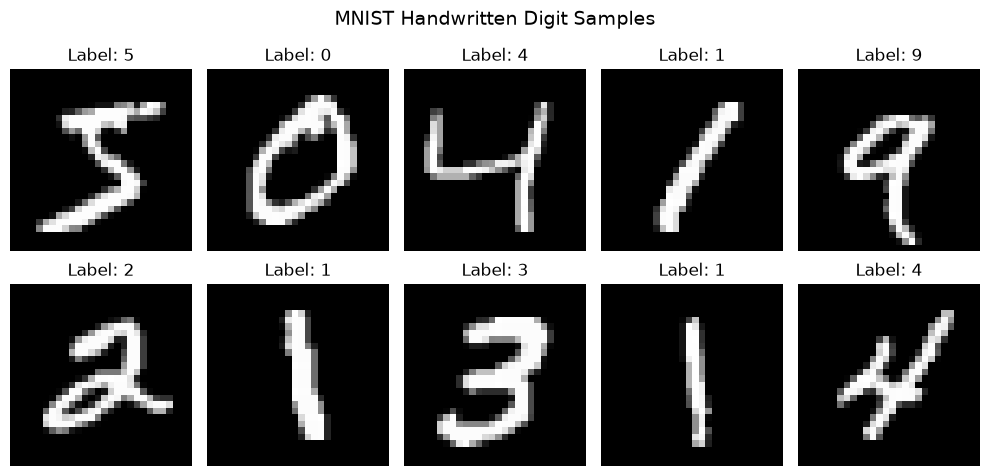

In [3]:
import matplotlib.pyplot as plt

# Create a figure containing 10 images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

# Display the first 10 images
for i, ax in enumerate(axes.flat):
    
    image, label = train_dataset[i]

    # Remove the channel dimension for visualization
    image = image.squeeze(0)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("MNIST Handwritten Digit Samples", fontsize=14)
plt.tight_layout()
plt.show()

### 2.2 Data Preparation and Batching

The original MNIST training dataset contains 60,000 images.

We divide this dataset into 54,000 training images and 6,000 validation images using a fixed random seed for reproducibility.

The official MNIST test dataset of 10,000 images is kept separate for final evaluation.

PyTorch DataLoaders are used to organize images into mini-batches of 64 samples.

Training data is shuffled to vary the order of samples across epochs, while validation and test data are processed without shuffling.

In [4]:
from torch.utils.data import DataLoader, random_split

# Configuration
BATCH_SIZE = 64
RANDOM_SEED = 42

# Split training data into training and validation subsets
train_subset, val_subset = random_split(
    train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(RANDOM_SEED)
)

# Create DataLoaders
train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))
print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training samples: 54000
Validation samples: 6000
Test samples: 10000

Training batches: 844
Validation batches: 94
Test batches: 157


In [5]:
# Retrieve one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)

# Flatten the images
flattened_images = images.view(images.size(0), -1)

print("Flattened batch shape:", flattened_images.shape)

Batch shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Flattened batch shape: torch.Size([64, 784])


## 3. Autoencoder Architecture

### 3.1 Baseline Fully Connected Autoencoder

We implement a fully connected autoencoder consisting of an encoder, a low-dimensional latent representation, and a decoder.

The encoder progressively reduces the input dimensionality:

**784 → 256 → 64 → 16**

The decoder reconstructs the original image dimensions:

**16 → 64 → 256 → 784**

The input MNIST images are flattened from 28 × 28 pixels into 784-dimensional vectors before being passed through the network.

ReLU activation functions introduce nonlinearity between hidden layers, while a Sigmoid activation in the output layer constrains reconstructed pixel values to the range [0, 1].

The initial latent dimension is set to 16. This value will be varied in subsequent experiments to investigate the relationship between compression and reconstruction quality.

### 3.2 PyTorch Implementation

The baseline autoencoder is implemented using PyTorch's `nn.Module`.

The encoder consists of three fully connected layers that progressively compress the input image into a 16-dimensional latent representation.

The decoder mirrors the encoder and reconstructs the original 784-dimensional image representation.

ReLU activations are used between hidden layers, and Sigmoid is applied to the final output.

In [6]:
import torch
from torch import nn

class Autoencoder(nn.Module):
    
    def __init__(self, latent_dim=16):
        super().__init__()

        # Encoder: 784 -> 256 -> 64 -> latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )

        # Decoder: latent_dim -> 64 -> 256 -> 784

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def forward(self, x):

        # Compress input into latent representation
        z = self.encoder(x)

        # Reconstruct image from latent representation
        reconstructed = self.decoder(z)

        return reconstructed

In [7]:
# Initialize the autoencoder
model = Autoencoder(latent_dim=16)

# Get one batch of MNIST images
images, labels = next(iter(train_loader))

# Perform a forward pass
with torch.no_grad():
    reconstructed = model(images)

    # Extract latent representations
    latent_vectors = model.encoder(images)

print("Original images:", images.shape)
print("Latent representations:", latent_vectors.shape)
print("Reconstructed images:", reconstructed.shape)

Original images: torch.Size([64, 1, 28, 28])
Latent representations: torch.Size([64, 16])
Reconstructed images: torch.Size([64, 1, 28, 28])


### 3.3 Model Parameter Analysis

We examine the number of trainable parameters in the baseline autoencoder.

Fully connected layers contain learnable weights and biases. The number of parameters depends on the input and output dimensions of each layer.

Understanding model size helps us evaluate architectural complexity and compare different autoencoder configurations.

In [8]:
# Count total trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total trainable parameters: {total_params:,}")

# Display parameters for each layer
print("\nParameters by layer:")

for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        print(f"{name}: {parameter.numel():,}")

Total trainable parameters: 437,664

Parameters by layer:
encoder.1.weight: 200,704
encoder.1.bias: 256
encoder.3.weight: 16,384
encoder.3.bias: 64
encoder.5.weight: 1,024
encoder.5.bias: 16
decoder.0.weight: 1,024
decoder.0.bias: 64
decoder.2.weight: 16,384
decoder.2.bias: 256
decoder.4.weight: 200,704
decoder.4.bias: 784


## 4. Reconstruction Loss

The autoencoder is trained to minimize the difference between the original input images and their reconstructions.

We use Mean Squared Error (MSE) as the reconstruction loss function.

MSE calculates the average squared difference between original and reconstructed pixel values.

A lower reconstruction loss indicates better pixel-level reconstruction accuracy.

The model parameters will be optimized using the Adam optimizer during training.

In [9]:
import torch
import torch.nn.functional as F

# Example original pixel values
original = torch.tensor([0.0, 0.5, 1.0, 0.8])

# Example reconstructed pixel values
predicted = torch.tensor([0.1, 0.4, 0.9, 0.6])

# Calculate MSE manually
manual_mse = ((original - predicted) ** 2).mean()

# Calculate MSE using PyTorch
pytorch_mse = F.mse_loss(predicted, original)

print("Manual MSE:", manual_mse.item())
print("PyTorch MSE:", pytorch_mse.item())

Manual MSE: 0.017500000074505806
PyTorch MSE: 0.017500000074505806


## 5. PyTorch Lightning Training Implementation

We use PyTorch Lightning to organize the training and validation procedures.

The Lightning module wraps the previously defined autoencoder architecture and implements three essential methods:
- `training_step()`: Computes reconstruction loss during training.
- `validation_step()`: Evaluates reconstruction performance on the validation dataset.
- `configure_optimizers()`: Configures the Adam optimizer.

Mean Squared Error is used as the reconstruction objective.

The initial learning rate is set to 0.001.

In [10]:
import lightning as L
import torch.nn.functional as F

class LitAutoencoder(L.LightningModule):

    def __init__(self, latent_dim=16, learning_rate=0.001):
        super().__init__()

        # Save hyperparameters for reproducibility
        self.save_hyperparameters()

        # Initialize our autoencoder
        self.model = Autoencoder(latent_dim=latent_dim)

        # Store the learning rate
        self.learning_rate = learning_rate

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        
        # Extract images from the batch
        images, _ = batch

        # Reconstruct images
        reconstructed = self(images)

        # Calculate reconstruction loss
        loss = F.mse_loss(reconstructed, images)

        # Log training loss
        self.log("train_loss", loss, on_step=False, on_epoch=True)

        return loss

    def validation_step(self, batch, batch_idx):

        # Extract images
        images, _ = batch

        # Reconstruct images
        reconstructed = self(images)

        # Calculate validation loss
        loss = F.mse_loss(reconstructed, images)

        # Log validation loss
        self.log("val_loss", loss, on_step=False, on_epoch=True)

        return loss

    def configure_optimizers(self):

        optimizer = torch.optim.Adam(
            self.parameters(),
            lr=self.learning_rate
        )

        return optimizer

In [11]:
# Initialize Lightning autoencoder
lit_model = LitAutoencoder(
    latent_dim=16,
    learning_rate=0.001
)

print(lit_model)

LitAutoencoder(
  (model): Autoencoder(
    (encoder): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=784, out_features=256, bias=True)
      (2): ReLU()
      (3): Linear(in_features=256, out_features=64, bias=True)
      (4): ReLU()
      (5): Linear(in_features=64, out_features=16, bias=True)
    )
    (decoder): Sequential(
      (0): Linear(in_features=16, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=784, bias=True)
      (5): Sigmoid()
      (6): Unflatten(dim=1, unflattened_size=(1, 28, 28))
    )
  )
)


### 5.1 Training Configuration

The baseline autoencoder is trained using PyTorch Lightning with the following configuration:
- **Dataset:** MNIST
- **Training samples:** 54,000
- **Validation samples:** 6,000
- **Batch size:** 64
- **Latent dimension:** 16
- **Optimizer:** Adam
- **Learning rate:** 0.001
- **Loss function:** Mean Squared Error (MSE)
- **Maximum epochs:** 10
- **Accelerator:** CPU

The training objective is to minimize reconstruction error between the original and reconstructed images.

Training and validation losses are monitored to evaluate learning progress and generalization.

In [12]:
# Configure the Lightning Trainer
trainer = L.Trainer(
    max_epochs=10,
    accelerator="cpu",
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
    num_sanity_val_steps=2
)

# Train the autoencoder
trainer.fit(
    model=lit_model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/Users/tusharrao/Documents/learning-generative-models/assignment-01-autoencoder/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type        | Params | Mode  | FLOPs
------------------------------------------------------
0 | model | Autoencoder | 437 K  | train | 0    
------------------------------------------------------
437 K     Trainable params
0         Non-trainable params
437 K     Total params
1.751     Total estimated model params size (MB)
16        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |                                                                                            …

/Users/tusharrao/Documents/learning-generative-models/assignment-01-autoencoder/.venv/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/tusharrao/Documents/learning-generative-models/assignment-01-autoencoder/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/Users/tusharrao/Documents/learning-generative-models/assignment-01-autoencoder/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader`

Training: |                                                                                                   …

Validation: |                                                                                                 …

...

Validation: |                                                                                                 …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

`Trainer.fit` stopped: `max_epochs=10` reached.


In [13]:
print("Final training metrics:")

for name, value in trainer.callback_metrics.items():
    print(f"{name}: {value.item():.6f}")

Final training metrics:
val_loss: 0.011857
train_loss: 0.011587


## 6. Reconstruction Evaluation

After training the baseline autoencoder for 10 epochs, we evaluate its reconstruction quality using previously unseen MNIST test images.

The model compresses each input image into a 16-dimensional latent representation and reconstructs it using the decoder.

We compare original and reconstructed images to qualitatively assess:
- Preservation of digit structure.
- Sharpness of reconstructed edges.
- Loss of fine details.
- Reconstruction artifacts.

This visual evaluation complements the numerical reconstruction loss.

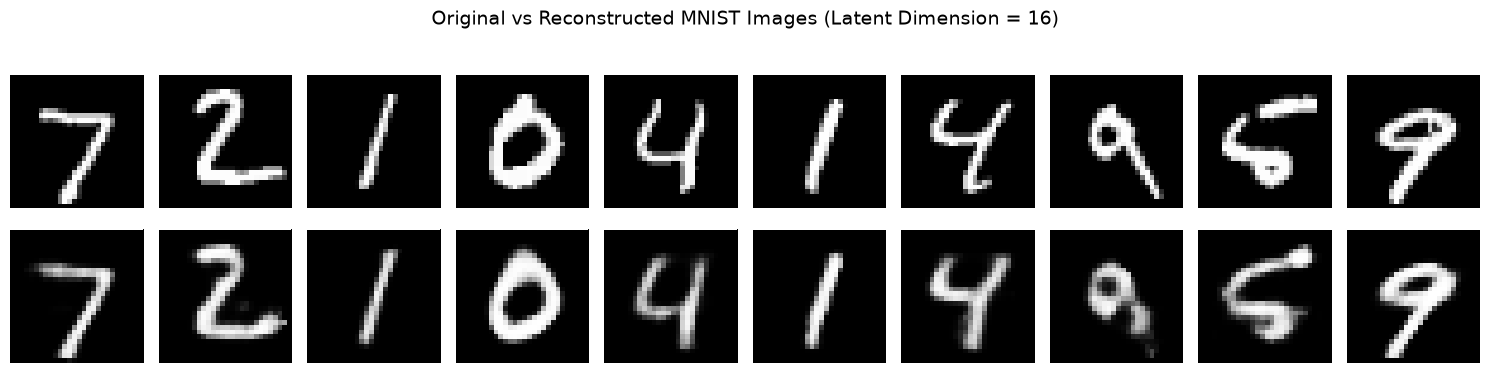

In [14]:
# Switch the model to evaluation mode
lit_model.eval()

# Get one batch of unseen test images
test_images, test_labels = next(iter(test_loader))

# Disable gradient calculations during evaluation
with torch.no_grad():
    reconstructed_images = lit_model(test_images)

# Create a figure with 2 rows and 10 columns
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):

    # Original image
    axes[0, i].imshow(
        test_images[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].axis("off")

    # Reconstructed image
    axes[1, i].imshow(
        reconstructed_images[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].axis("off")

# Add row labels
axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)

plt.suptitle(
    "Original vs Reconstructed MNIST Images (Latent Dimension = 16)",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 6.1 Qualitative Reconstruction Analysis

The baseline autoencoder successfully reconstructs recognizable handwritten digits from previously unseen MNIST test images using a 16-dimensional latent representation.

**Key observations:**
1. **Structural preservation:** The reconstructed images retain the overall shapes and identities of the original digits.
2. **Blurring:** Reconstructed digits exhibit smoother edges and reduced sharpness compared with the originals.
3. **Loss of fine details:** Some thin strokes and subtle handwriting variations are not fully preserved.
4. **Variation in reconstruction quality:** Certain digits show more noticeable distortions than others.

These results suggest that the autoencoder has learned useful compressed representations of handwritten digits.

However, reconstruction quality is limited by the model architecture, latent representation capacity, and MSE-based training objective.

**Hypothesis for further investigation:** Increasing the latent dimension may reduce reconstruction error and improve the preservation of fine image details.

This hypothesis will be evaluated by comparing autoencoders with different latent dimensions.

### 6.2 Quantitative Reconstruction Evaluation

The initial autoencoder is evaluated on the validation dataset using Mean Squared Error (MSE).

The reconstruction error is calculated across all pixels in the 6,000 validation images.

This preliminary evaluation provides an initial measure of reconstruction quality.

Subsequent experiments compare model configurations using validation performance. The held-out test dataset is reserved for the final evaluation of the selected model in Section 10.

In [39]:
# Evaluate the initial autoencoder on the validation dataset

lit_model.eval()

total_squared_error = 0.0
total_pixels = 0

with torch.no_grad():

    for images, _ in val_loader:

        # Reconstruct validation images
        reconstructed = lit_model(images)

        # Calculate squared reconstruction errors
        squared_error = (reconstructed - images) ** 2

        # Accumulate errors across all images
        total_squared_error += squared_error.sum().item()

        # Count the total number of pixels
        total_pixels += images.numel()

# Calculate the overall validation MSE
initial_val_mse = total_squared_error / total_pixels

print(f"Total validation images: {len(val_subset):,}")
print(f"Total evaluated pixels: {total_pixels:,}")
print(f"Initial model validation MSE: {initial_val_mse:.6f}")

Total validation images: 6,000
Total evaluated pixels: 4,704,000
Initial model validation MSE: 0.011857


## 7. Training Dynamics

To analyze the learning process, we record training and validation reconstruction losses after each epoch.

A PyTorch Lightning callback is used to collect epoch-level metrics without modifying the autoencoder architecture.

These metrics will be used to visualize convergence, compare training and validation performance, and identify potential signs of overfitting.

In [16]:
from lightning.pytorch.callbacks import Callback

class LossHistory(Callback):

    def __init__(self):
        super().__init__()

        self.train_losses = []
        self.val_losses = []

    def on_train_epoch_end(self, trainer, pl_module):

        train_loss = trainer.callback_metrics.get("train_loss")

        if train_loss is not None:
            self.train_losses.append(train_loss.item())

    def on_validation_epoch_end(self, trainer, pl_module):

        # Ignore the initial validation sanity check
        if trainer.sanity_checking:
            return

        val_loss = trainer.callback_metrics.get("val_loss")

        if val_loss is not None:
            self.val_losses.append(val_loss.item())

# Initialize the callback
loss_history = LossHistory()

print("Loss history callback initialized successfully.")
print("Training losses:", loss_history.train_losses)
print("Validation losses:", loss_history.val_losses)

Loss history callback initialized successfully.
Training losses: []
Validation losses: []


### 7.1 Baseline Training with Metric Recording

To examine training dynamics, we retrain the baseline autoencoder from randomly initialized weights.

The architecture and training hyperparameters remain unchanged:
- Latent dimension: 16
- Learning rate: 0.001
- Batch size: 64
- Epochs: 10
- Optimizer: Adam
- Reconstruction loss: MSE

A fixed random seed is used to improve reproducibility.

Training and validation losses are recorded after every epoch using the `LossHistory` callback.

This experiment allows us to visualize convergence and examine the relationship between training and validation performance.

In [17]:
# Set random seed for reproducibility
L.seed_everything(42)

# Create a fresh baseline model
baseline_model = LitAutoencoder(
    latent_dim=16,
    learning_rate=0.001
)

# Create a fresh loss history callback
baseline_history = LossHistory()

# Configure the trainer
baseline_trainer = L.Trainer(
    max_epochs=10,
    accelerator="cpu",
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
    num_sanity_val_steps=2,
    callbacks=[baseline_history]
)

# Train the baseline model
baseline_trainer.fit(
    model=baseline_model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

# Display recorded losses
print("\nTraining losses:")
print(baseline_history.train_losses)
print("\nValidation losses:")
print(baseline_history.val_losses)

Seed set to 42
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type        | Params | Mode  | FLOPs
------------------------------------------------------
0 | model | Autoencoder | 437 K  | train | 0    
------------------------------------------------------
437 K     Trainable params
0         Non-trainable params
437 K     Total params
1.751     Total estimated model params size (MB)
16        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |                                                                                            …

Training: |                                                                                                   …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

...

Validation: |                                                                                                 …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

`Trainer.fit` stopped: `max_epochs=10` reached.



Training losses:
[0.044527310878038406, 0.02421310916543007, 0.019359322264790535, 0.017093505710363388, 0.01539012510329485, 0.01413691882044077, 0.013250069692730904, 0.012563212774693966, 0.012061008252203465, 0.011671238578855991]

Validation losses:
[0.02782534621655941, 0.021350262686610222, 0.018276771530508995, 0.01636631414294243, 0.01501196064054966, 0.01397232711315155, 0.013290836475789547, 0.012475967407226562, 0.012192489579319954, 0.011822488158941269]


### 7.2 Training and Validation Loss Curves

We visualize the reconstruction loss across ten training epochs to evaluate convergence and generalization.

The training and validation losses are plotted together to examine whether the model improves consistently and whether there are signs of overfitting.

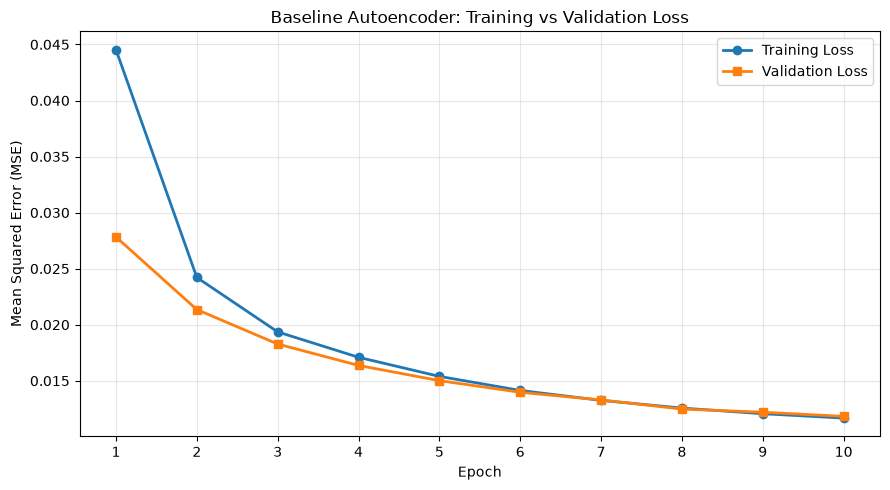

In [18]:
import matplotlib.pyplot as plt

# Epoch numbers
epochs = range(1, len(baseline_history.train_losses) + 1)

# Create figure
plt.figure(figsize=(9, 5))

# Plot training loss
plt.plot(
    epochs,
    baseline_history.train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

# Plot validation loss
plt.plot(
    epochs,
    baseline_history.val_losses,
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

# Add labels and title
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Baseline Autoencoder: Training vs Validation Loss")

# Show all epoch numbers
plt.xticks(list(epochs))

# Add legend and grid
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 Training Dynamics Analysis

The training and validation loss curves show consistent improvement throughout the ten training epochs.

**Key findings:**

1. **Successful optimization:** Training MSE decreased from approximately 0.0445 to 0.0117, indicating that the model successfully learned to reconstruct MNIST images.
2. **Generalization:** Validation MSE decreased from approximately 0.0278 to 0.0118, suggesting that the learned representations generalize to unseen validation images.
3. **No clear overfitting:** Both curves decrease throughout training, and their final values are close. No substantial divergence is observed.
4. **Diminishing improvements:** Loss reduction becomes smaller during later epochs, suggesting that training is progressing toward convergence.

**Conclusion:** The baseline autoencoder demonstrates stable learning and reasonable reconstruction performance. Additional epochs might further reduce reconstruction error, but their benefit would need to be evaluated experimentally.

## 8. Experiment 1: Effect of Latent Dimension

### 8.1 Research Question
How does the dimensionality of the latent representation affect autoencoder reconstruction quality?

### 8.2 Hypothesis
Increasing the latent dimension from 16 to 64 is expected to improve reconstruction quality because the encoder can preserve more information about the input image.

### 8.3 Experimental Setup
Two fully connected autoencoders are compared:
- **Baseline:** Latent dimension = 16
- **Experiment:** Latent dimension = 64

Both models use the same training and validation datasets, batch size, optimizer, learning rate, reconstruction loss, and number of training epochs.

A fixed random seed is used to improve reproducibility.

Reconstruction quality will be compared using validation MSE and visual inspection of reconstructed images.

Increasing latent dimension also increases the number of trainable parameters, which will be considered when interpreting the results.

In [19]:
# Set random seed
L.seed_everything(42)

# Initialize the experimental autoencoder
model_64 = LitAutoencoder(
    latent_dim=64,
    learning_rate=0.001
)

# Count trainable parameters
params_64 = sum(
    p.numel()
    for p in model_64.parameters()
    if p.requires_grad
)

# Display model information
print("Latent dimension:", model_64.hparams.latent_dim)
print(f"Trainable parameters: {params_64:,}")

# Compare with baseline
params_16 = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

print(f"\nBaseline parameters (latent=16): {params_16:,}")
print(f"Experiment parameters (latent=64): {params_64:,}")
print(f"Additional parameters: {params_64 - params_16:,}")

Seed set to 42


Latent dimension: 64
Trainable parameters: 443,856

Baseline parameters (latent=16): 437,664
Experiment parameters (latent=64): 443,856
Additional parameters: 6,192


### 8.4 Training the 64-Dimensional Autoencoder

The experimental autoencoder is trained for 10 epochs using the same dataset split, optimizer, learning rate, batch size, and reconstruction loss as the baseline.

Training and validation losses are recorded using the previously implemented `LossHistory` callback.

The resulting validation performance will be compared with the 16-dimensional baseline to evaluate the effect of increasing latent representation capacity.

In [20]:
# Create a callback to record losses
history_64 = LossHistory()

# Configure the trainer
trainer_64 = L.Trainer(
    max_epochs=10,
    accelerator="cpu",
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
    num_sanity_val_steps=2,
    callbacks=[history_64]
)

# Train the 64-dimensional autoencoder
trainer_64.fit(
    model=model_64,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

# Display training results
print("\nTraining losses:")
print(history_64.train_losses)
print("\nValidation losses:")
print(history_64.val_losses)

# Compare final validation losses
baseline_val_mse = baseline_history.val_losses[-1]
experiment_val_mse = history_64.val_losses[-1]

print("\nFinal Validation MSE Comparison")
print(f"Latent dimension 16: {baseline_val_mse:.6f}")
print(f"Latent dimension 64: {experiment_val_mse:.6f}")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type        | Params | Mode  | FLOPs
------------------------------------------------------
0 | model | Autoencoder | 443 K  | train | 0    
------------------------------------------------------
443 K     Trainable params
0         Non-trainable params
443 K     Total params
1.775     Total estimated model params size (MB)
16        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |                                                                                            …

Training: |                                                                                                   …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

...

Validation: |                                                                                                 …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

`Trainer.fit` stopped: `max_epochs=10` reached.



Training losses:
[0.041553910821676254, 0.020847994834184647, 0.01624208875000477, 0.013520202599465847, 0.011972333304584026, 0.010916570201516151, 0.010060456581413746, 0.009387237951159477, 0.008866026066243649, 0.008444523438811302]

Validation losses:
[0.024751024320721626, 0.018364638090133667, 0.01482625026255846, 0.012748307548463345, 0.011642481200397015, 0.01066816970705986, 0.010030255652964115, 0.009349657222628593, 0.008903415873646736, 0.008654319681227207]

Final Validation MSE Comparison
Latent dimension 16: 0.011822
Latent dimension 64: 0.008654


### 8.5 Validation Loss Comparison

We compare the validation reconstruction losses of the 16-dimensional and 64-dimensional autoencoders across ten training epochs.

Both models were trained using the same dataset split, optimizer, learning rate, batch size, and training duration.

The comparison helps determine whether increasing latent representation capacity improves reconstruction performance.

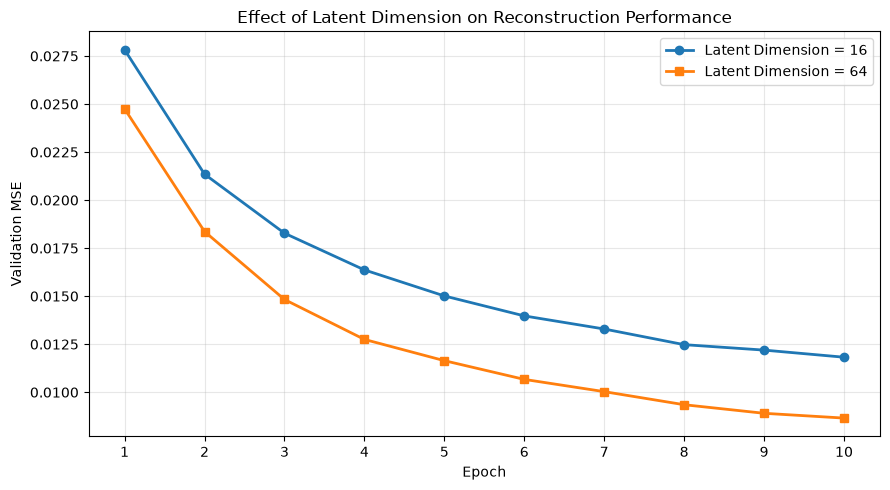

In [21]:
# Epoch numbers
epochs = range(1, 11)

# Create figure
plt.figure(figsize=(9, 5))

# Baseline model
plt.plot(
    epochs,
    baseline_history.val_losses,
    marker="o",
    linewidth=2,
    label="Latent Dimension = 16"
)

# Experimental model
plt.plot(
    epochs,
    history_64.val_losses,
    marker="s",
    linewidth=2,
    label="Latent Dimension = 64"
)

# Labels and title
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Effect of Latent Dimension on Reconstruction Performance")

plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8.6 Experimental Results and Discussion

The experiment investigated whether increasing the latent representation from 16 to 64 dimensions improves reconstruction performance.

**Results:**
| Metric | Latent = 16 | Latent = 64 |
|---|---:|---:|
| Trainable parameters | 437,664 | 443,856 |
| Final training MSE | 0.011671 | 0.008445 |
| Final validation MSE | 0.011822 | 0.008654 |

**Key findings:**
1. **Improved reconstruction accuracy:** Increasing the latent dimension from 16 to 64 reduced validation MSE from approximately 0.01182 to 0.00865, representing a relative improvement of approximately 26.8%.
2. **Consistent improvement:** The 64-dimensional model achieved lower validation loss across all ten epochs.
3. **Increased representation capacity:** A larger latent space allows the encoder to retain more information about the original images, potentially improving reconstruction fidelity.
4. **Moderate parameter increase:** The number of trainable parameters increased by approximately 1.4%, from 437,664 to 443,856.

**Interpretation:**

The results support the hypothesis that increasing latent representation capacity can improve reconstruction quality.

However, the experiment also changes the model's parameter count, and each configuration was trained only once. Additional random seeds would help determine whether the observed improvement is consistent across independent runs.

**Conclusion:**

For the evaluated MNIST autoencoder architecture and training configuration, the 64-dimensional latent representation achieved better validation reconstruction performance than the 16-dimensional baseline.

### 8.7 Qualitative Comparison of Latent Dimensions

To complement the quantitative comparison, we visually compare reconstructions produced by the 16-dimensional and 64-dimensional autoencoders.

Both models reconstruct the same ten MNIST images, allowing a direct comparison of digit structure, edge sharpness, and preservation of fine details.

The objective is to determine whether the lower validation MSE achieved by the larger latent representation corresponds to visibly improved reconstruction quality.

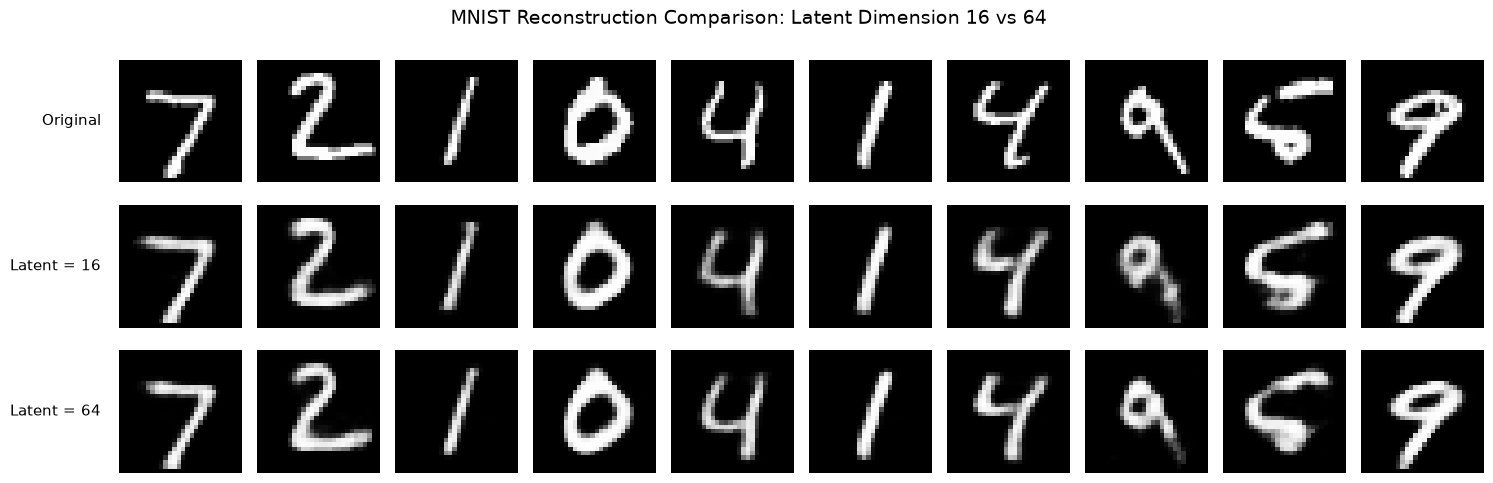

In [22]:
# Switch both models to evaluation mode
baseline_model.eval()
model_64.eval()

# Use the same test images for both models
comparison_images, _ = next(iter(test_loader))

# Generate reconstructions without calculating gradients
with torch.no_grad():
    recon_16 = baseline_model(comparison_images)
    recon_64 = model_64(comparison_images)

# Create a figure with 3 rows and 10 columns
fig, axes = plt.subplots(3, 10, figsize=(15, 5))

for i in range(10):

    # Original image
    axes[0, i].imshow(
        comparison_images[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Reconstruction: latent dimension 16
    axes[1, i].imshow(
        recon_16[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Reconstruction: latent dimension 64
    axes[2, i].imshow(
        recon_64[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for row in range(3):
        axes[row, i].axis("off")

# Add row labels
row_labels = [
    "Original",
    "Latent = 16",
    "Latent = 64"
]

for row, label in enumerate(row_labels):
    axes[row, 0].text(
        -0.15,
        0.5,
        label,
        transform=axes[row, 0].transAxes,
        fontsize=11,
        ha="right",
        va="center"
    )

plt.suptitle(
    "MNIST Reconstruction Comparison: Latent Dimension 16 vs 64",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 8.8 Qualitative Reconstruction Comparison

The reconstruction comparison demonstrates that both autoencoders successfully preserve the overall structure of handwritten MNIST digits.

**Key observations:**
1. **Digit recognition:** Both models produce recognizable reconstructions of the selected test images.
2. **Improved detail preservation:** The 64-dimensional model generally reconstructs digit strokes and boundaries more accurately than the 16-dimensional baseline.
3. **Reduced distortion:** Some digits, particularly those with more complex stroke structures, show improved reconstruction with the larger latent representation.
4. **Remaining limitations:** Both models produce slightly blurred images, indicating that increasing latent dimension alone does not eliminate reconstruction artifacts.
5. **Numerical versus perceptual quality:** Although the 64-dimensional model reduces validation MSE by approximately 26.8%, the visual improvement is relatively modest for several digits.

**Conclusion:**

The qualitative results are broadly consistent with the quantitative evaluation. Increasing latent dimension improves reconstruction accuracy, although the degree of visible improvement varies across individual images.

The results support the hypothesis that a larger latent representation can preserve more information about the original image.

## 9. Experiment 2: Convolutional Autoencoder

### 9.1 Motivation
Fully connected autoencoders flatten images into one-dimensional vectors before processing them.

Convolutional autoencoders instead exploit the spatial structure of images by learning local patterns through convolutional filters.

This experiment investigates whether a convolutional architecture can improve reconstruction quality compared with the fully connected baseline.

### 9.2 Understanding Convolutional Layers
A two-dimensional convolutional layer applies learnable filters across an image to extract spatial features.

The number of input channels, output channels, kernel size, stride, and padding determine how the layer processes the input.

In [23]:
# Create a convolutional layer
conv_layer = nn.Conv2d(
    in_channels=1,
    out_channels=16,
    kernel_size=3,
    stride=1,
    padding=1
)

# Retrieve one batch of MNIST images
images, _ = next(iter(train_loader))

# Pass images through the convolutional layer
with torch.no_grad():
    conv_output = conv_layer(images)

print("Input shape:", images.shape)
print("Output shape:", conv_output.shape)

# Count the trainable parameters
conv_params = sum(
    p.numel() for p in conv_layer.parameters()
)

print("Trainable parameters:", conv_params)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 16, 28, 28])
Trainable parameters: 160


### 9.3 Spatial Downsampling Using Convolutions

Convolutional encoders can progressively reduce image resolution using convolutional layers with a stride greater than one.

In this experiment, two convolutional layers with stride 2 are applied to MNIST images.

The first layer reduces the spatial dimensions from 28 × 28 to 14 × 14, while the second reduces them from 14 × 14 to 7 × 7.

At the same time, the number of feature channels increases from 1 to 16 and then to 32.

This demonstrates how convolutional encoders learn spatial feature representations at progressively lower resolutions.

In [24]:
# First convolutional layer
conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=16,
    kernel_size=3,
    stride=2,
    padding=1
)

# Second convolutional layer
conv2 = nn.Conv2d(
    in_channels=16,
    out_channels=32,
    kernel_size=3,
    stride=2,
    padding=1
)

# Retrieve one batch
images, _ = next(iter(train_loader))

# Pass images through both layers
with torch.no_grad():
    output1 = conv1(images)
    output2 = conv2(output1)

print("Original images:", images.shape)
print("After first convolution:", output1.shape)
print("After second convolution:", output2.shape)

Original images: torch.Size([64, 1, 28, 28])
After first convolution: torch.Size([64, 16, 14, 14])
After second convolution: torch.Size([64, 32, 7, 7])


### 9.4 Spatial Upsampling Using Transposed Convolutions

The decoder must reconstruct the original image resolution from lower-resolution feature maps.

Transposed convolutional layers can learn to increase spatial dimensions while transforming feature representations.

We test two transposed convolutional layers that increase spatial resolution from 7 × 7 to 14 × 14 and finally to 28 × 28.

This operation will form the basis of our convolutional decoder.

In [25]:
# First transposed convolution
deconv1 = nn.ConvTranspose2d(
    in_channels=32,
    out_channels=16,
    kernel_size=3,
    stride=2,
    padding=1,
    output_padding=1
)

# Second transposed convolution
deconv2 = nn.ConvTranspose2d(
    in_channels=16,
    out_channels=1,
    kernel_size=3,
    stride=2,
    padding=1,
    output_padding=1
)

# Use the output from our previous convolutional encoder
with torch.no_grad():
    reconstructed_features = deconv1(output2)
    reconstructed_images = deconv2(reconstructed_features)

print("Encoder output:", output2.shape)
print("After first transposed convolution:", reconstructed_features.shape)
print("After second transposed convolution:", reconstructed_images.shape)

Encoder output: torch.Size([64, 32, 7, 7])
After first transposed convolution: torch.Size([64, 16, 14, 14])
After second transposed convolution: torch.Size([64, 1, 28, 28])


### 9.5 Convolutional Autoencoder Architecture

We implement a convolutional autoencoder that preserves spatial information during feature extraction.

The encoder uses two convolutional layers with stride 2 to reduce image resolution from 28 × 28 to 7 × 7.

The resulting feature maps are flattened and projected into a 16-dimensional latent representation.

The decoder maps the latent vector back into spatial feature maps and uses two transposed convolutional layers to reconstruct the original image resolution.

ReLU activations are used in intermediate layers, while a final Sigmoid activation constrains reconstructed pixel values to the range [0, 1].

The latent dimension is fixed at 16 to enable comparison with the fully connected baseline.

In [26]:
class ConvAutoencoder(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        # Encoder: Image -> Latent representation
        self.encoder = nn.Sequential(

            # [B, 1, 28, 28] -> [B, 16, 14, 14]
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # [B, 16, 14, 14] -> [B, 32, 7, 7]
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # [B, 32, 7, 7] -> [B, 1568]
            nn.Flatten(),
            
            # [B, 1568] -> [B, 16]
            nn.Linear(32 * 7 * 7, latent_dim)
        )

        # Decoder: Latent representation -> Reconstructed image
        self.decoder = nn.Sequential(

            # [B, 16] -> [B, 1568]
            nn.Linear(latent_dim, 32 * 7 * 7),
            nn.ReLU(),

            # [B, 1568] -> [B, 32, 7, 7]
            nn.Unflatten(1, (32, 7, 7)),

            # [B, 32, 7, 7] -> [B, 16, 14, 14]
            nn.ConvTranspose2d(
                in_channels=32,
                out_channels=16,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            # [B, 16, 14, 14] -> [B, 1, 28, 28]
            nn.ConvTranspose2d(
                in_channels=16,
                out_channels=1,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):

        # Compress image
        z = self.encoder(x)

        # Reconstruct image
        reconstructed = self.decoder(z)

        return reconstructed

In [27]:
# Initialize convolutional autoencoder
conv_model = ConvAutoencoder(latent_dim=16)

# Retrieve one batch
images, _ = next(iter(train_loader))

# Test the forward pass
with torch.no_grad():
    latent_vectors = conv_model.encoder(images)
    reconstructed = conv_model(images)

# Count trainable parameters
conv_params = sum(
    p.numel()
    for p in conv_model.parameters()
    if p.requires_grad
)

print("Original images:", images.shape)
print("Latent representations:", latent_vectors.shape)
print("Reconstructed images:", reconstructed.shape)
print(f"\nCNN trainable parameters: {conv_params:,}")

Original images: torch.Size([64, 1, 28, 28])
Latent representations: torch.Size([64, 16])
Reconstructed images: torch.Size([64, 1, 28, 28])

CNN trainable parameters: 61,329


### 9.6 Model Complexity Comparison

The convolutional autoencoder contains 61,329 trainable parameters, compared with 437,664 parameters in the fully connected baseline.

This represents approximately an 86% reduction in parameter count.

The reduction is primarily due to convolutional weight sharing, where filters are reused across spatial locations rather than learning independent weights for every input-output connection.

Both architectures use a 16-dimensional latent representation, allowing reconstruction performance to be compared under the same latent dimensionality constraint.

However, the architectures differ substantially in parameter count and inductive biases. Therefore, performance differences cannot be attributed exclusively to convolutional operations.

In [28]:
class LitReconstructionModel(L.LightningModule):

    def __init__(self, autoencoder, learning_rate=0.001):
        super().__init__()

        # Store the autoencoder architecture
        self.model = autoencoder

        # Store the learning rate
        self.learning_rate = learning_rate

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):

        # Extract images
        images, _ = batch

        # Reconstruct images
        reconstructed = self(images)

        # Calculate reconstruction loss
        loss = F.mse_loss(reconstructed, images)

        # Record training loss
        self.log(
            "train_loss",
            loss,
            on_step=False,
            on_epoch=True
        )
        return loss

    def validation_step(self, batch, batch_idx):

        # Extract images
        images, _ = batch

        # Reconstruct images
        reconstructed = self(images)

        # Calculate validation loss
        loss = F.mse_loss(reconstructed, images)

        # Record validation loss
        self.log(
            "val_loss",
            loss,
            on_step=False,
            on_epoch=True
        )
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.learning_rate
        )

In [29]:
# Set random seed
L.seed_everything(42)

# Create a fresh convolutional autoencoder
cnn_autoencoder = ConvAutoencoder(latent_dim=16)

# Wrap it in PyTorch Lightning
cnn_model = LitReconstructionModel(
    autoencoder=cnn_autoencoder,
    learning_rate=0.001
)

# Verify the model
print(cnn_model)

# Count trainable parameters
cnn_total_params = sum(
    p.numel()
    for p in cnn_model.parameters()
    if p.requires_grad
)

print(f"\nCNN trainable parameters: {cnn_total_params:,}")

Seed set to 42


LitReconstructionModel(
  (model): ConvAutoencoder(
    (encoder): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): Flatten(start_dim=1, end_dim=-1)
      (5): Linear(in_features=1568, out_features=16, bias=True)
    )
    (decoder): Sequential(
      (0): Linear(in_features=16, out_features=1568, bias=True)
      (1): ReLU()
      (2): Unflatten(dim=1, unflattened_size=(32, 7, 7))
      (3): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
      (4): ReLU()
      (5): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
      (6): Sigmoid()
    )
  )
)

CNN trainable parameters: 61,329


### 9.7 Experimental Hypothesis and Training Configuration

**Research question:** Can a convolutional autoencoder achieve better MNIST reconstruction accuracy than a fully connected autoencoder while using fewer trainable parameters?

**Hypothesis:** Convolutional layers may improve reconstruction quality by exploiting spatial relationships between neighboring pixels and learning reusable local features.

To compare the architectures, both models use:
- Dataset: MNIST
- Training samples: 54,000
- Validation samples: 6,000
- Latent dimension: 16
- Batch size: 64
- Training epochs: 10
- Optimizer: Adam
- Learning rate: 0.001
- Reconstruction loss: Mean Squared Error (MSE)
- Random seed: 42

The fully connected baseline contains 437,664 trainable parameters, while the convolutional autoencoder contains 61,329.

The primary comparison metric is validation MSE. Lower values indicate better pixel-level reconstruction accuracy.

Because the architectures differ in both structure and parameter count, the experiment evaluates their overall performance under a shared training configuration rather than isolating the effect of convolution alone.

In [30]:
# Create a separate loss history for the CNN experiment
cnn_history = LossHistory()

# Configure the trainer
cnn_trainer = L.Trainer(
    max_epochs=10,
    accelerator="cpu",
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
    num_sanity_val_steps=2,
    callbacks=[cnn_history]
)

# Train the convolutional autoencoder
cnn_trainer.fit(
    cnn_model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

# Display recorded losses
print("\nCNN Training Losses:")
print(cnn_history.train_losses)

print("\nCNN Validation Losses:")
print(cnn_history.val_losses)

print(
    f"\nFinal CNN Training MSE: "
    f"{cnn_history.train_losses[-1]:.6f}"
)

print(
    f"Final CNN Validation MSE: "
    f"{cnn_history.val_losses[-1]:.6f}"
)

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type            | Params | Mode  | FLOPs
----------------------------------------------------------
0 | model | ConvAutoencoder | 61.3 K | train | 0    
----------------------------------------------------------
61.3 K    Trainable params
0         Non-trainable params
61.3 K    Total params
0.245     Total estimated model params size (MB)
16        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |                                                                                            …

Training: |                                                                                                   …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

...

Validation: |                                                                                                 …

Validation: |                                                                                                 …

Validation: |                                                                                                 …

`Trainer.fit` stopped: `max_epochs=10` reached.



CNN Training Losses:
[0.04207848384976387, 0.016917634755373, 0.014268542639911175, 0.012914681807160378, 0.012085480615496635, 0.01152415294200182, 0.011091277934610844, 0.01073520164936781, 0.010458864271640778, 0.01020974200218916]

CNN Validation Losses:
[0.01937582902610302, 0.015438541769981384, 0.013661359436810017, 0.012516685761511326, 0.011948551051318645, 0.011408789083361626, 0.011070902459323406, 0.010836323723196983, 0.010579610243439674, 0.010345610789954662]

Final CNN Training MSE: 0.010210
Final CNN Validation MSE: 0.010346


### 9.8 Quantitative Results and Learning Curve Comparison

After 10 training epochs, the convolutional autoencoder achieved a validation MSE of approximately 0.010346, compared with 0.011822 for the fully connected baseline.

This corresponds to a relative reduction in validation MSE of approximately 12.5%.

The convolutional model also uses approximately 86% fewer trainable parameters.

To investigate convergence behavior, we compare the validation learning curves of both architectures across all 10 epochs.

This comparison helps determine whether the performance advantage is consistent throughout training or emerges only after additional optimization.

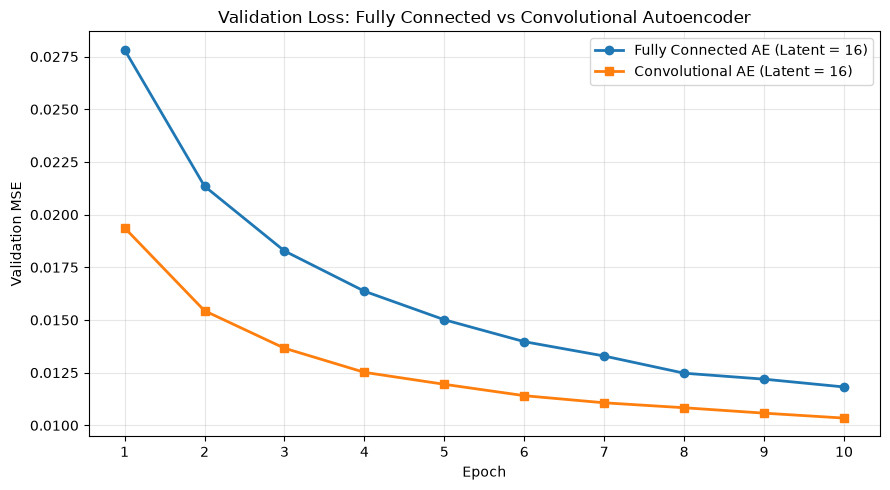

In [31]:
# Compare validation learning curves
epochs = range(1, 11)

plt.figure(figsize=(9, 5))

# Fully connected baseline
plt.plot(
    epochs,
    baseline_history.val_losses,
    marker="o",
    linewidth=2,
    label="Fully Connected AE (Latent = 16)"
)

# Convolutional autoencoder
plt.plot(
    epochs,
    cnn_history.val_losses,
    marker="s",
    linewidth=2,
    label="Convolutional AE (Latent = 16)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Validation Loss: Fully Connected vs Convolutional Autoencoder")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 9.9 Learning Curve Analysis

The validation learning curves show that both autoencoders improve consistently throughout the 10 training epochs.

**Key observations:**
1. **Faster initial learning:** The convolutional autoencoder achieves a validation MSE of approximately 0.019376 after the first epoch, compared with 0.027825 for the fully connected baseline.
2. **Consistent performance advantage:** The convolutional model maintains a lower validation MSE across all 10 epochs.
3. **Final reconstruction accuracy:** After 10 epochs, the convolutional model achieves a validation MSE of 0.010346, compared with 0.011822 for the fully connected baseline. This represents an improvement of approximately 12.5%.
4. **Parameter efficiency:** The convolutional model achieves better reconstruction accuracy using 61,329 trainable parameters, compared with 437,664 parameters in the fully connected model.
5. **Training stability:** Both models exhibit steadily decreasing validation losses, with no clear evidence of overfitting during the observed training period.
6. **Diminishing returns:** Improvements become progressively smaller toward the final epochs, although further training might still improve performance.

**Interpretation:**

The results support the hypothesis that convolutional architectures are effective for image reconstruction because they exploit spatial relationships and reuse learned filters across image locations.

The convolutional autoencoder demonstrates better validation reconstruction accuracy and greater parameter efficiency under the tested configuration.

However, these findings are based on one training run per architecture. Additional experiments with multiple random seeds would be required to assess the consistency of the observed advantage.

### 9.10 Qualitative Reconstruction Comparison

To complement the quantitative evaluation, we compare reconstructed images from the fully connected and convolutional autoencoders.

Both models reconstruct the same 10 MNIST test images.

The comparison includes the original images, reconstructions from the fully connected baseline, and reconstructions from the convolutional autoencoder.

This visualization allows us to investigate differences in digit structure, stroke preservation, sharpness, and reconstruction artifacts.

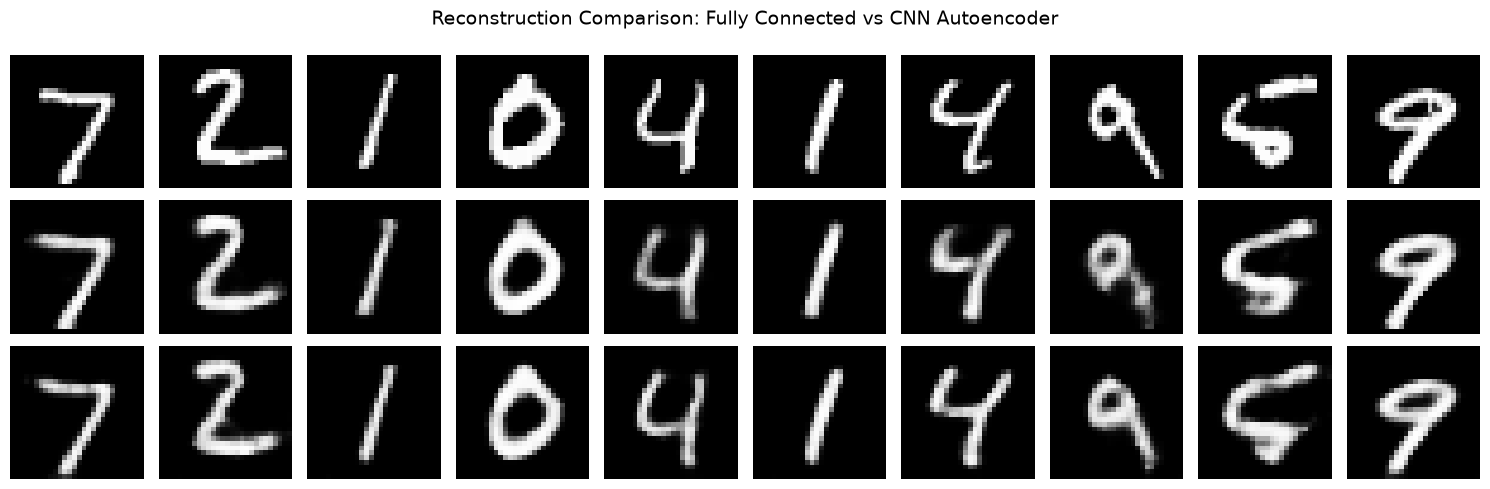

In [32]:
# Switch both models to evaluation mode
baseline_model.eval()
cnn_model.eval()

# Retrieve the same test images for both models
comparison_images, _ = next(iter(test_loader))

# Generate reconstructions without calculating gradients
with torch.no_grad():

    # Fully connected reconstructions
    fc_reconstructions = baseline_model(comparison_images)

    # Convolutional reconstructions
    cnn_reconstructions = cnn_model(comparison_images)

# Number of images to display
n_images = 10

# Create visualization
fig, axes = plt.subplots(
    3,
    n_images,
    figsize=(15, 5)
)

row_labels = [
    "Original",
    "Fully Connected",
    "Convolutional"
]

for i in range(n_images):

    # Original image
    axes[0, i].imshow(
        comparison_images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Fully connected reconstruction
    axes[1, i].imshow(
        fc_reconstructions[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # CNN reconstruction
    axes[2, i].imshow(
        cnn_reconstructions[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Remove axis ticks
    for row in range(3):
        axes[row, i].axis("off")

# Add row labels
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(
        label,
        fontsize=11,
        rotation=90,
        labelpad=15
    )
    axes[row, 0].yaxis.set_label_coords(-0.2, 0.5)

plt.suptitle(
    "Reconstruction Comparison: Fully Connected vs CNN Autoencoder",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 9.11 Qualitative Reconstruction Analysis

The visual comparison demonstrates that both the fully connected and convolutional autoencoders successfully reconstruct recognizable handwritten digits.

**Key observations:**
1. **Preservation of digit structure:** Both architectures retain the overall shapes and identities of the selected MNIST digits.
2. **Improved stroke reconstruction:** The convolutional autoencoder appears to preserve certain local details more accurately. For example, the lower stroke of the digit 2 and the descending stroke of the digit 9 appear more continuous in the convolutional reconstructions.
3. **Similar performance on simple digits:** Some digits, particularly those with relatively simple stroke structures, show only minor visual differences between the two architectures.
4. **Remaining reconstruction artifacts:** Both models produce slightly blurred reconstructions and occasionally lose fine details.
5. **Consistency with quantitative evaluation:** The qualitative observations are broadly consistent with the approximately 12.5% lower validation MSE achieved by the convolutional model. However, the visual improvements are not equally noticeable across all images.

**Conclusion:**
The convolutional autoencoder achieves better validation reconstruction accuracy while using substantially fewer trainable parameters.

These findings support the hypothesis that convolutional architectures can provide an effective inductive bias for image reconstruction by exploiting local spatial relationships.

Nevertheless, the comparison is limited to one training run per architecture, and the models differ in parameter count as well as architectural structure.

## 10. Final Model Selection and Test Evaluation

### 10.1 Model Selection
Three autoencoder configurations were evaluated using the validation dataset.
| Model | Latent Dimension | Final Validation MSE |
|---|---:|---:|
| Fully Connected Autoencoder | 16 | 0.011822 |
| Fully Connected Autoencoder | 64 | **0.008654** |
| Convolutional Autoencoder | 16 | 0.010346 |

The fully connected autoencoder with a 64-dimensional latent representation achieved the lowest validation MSE and was selected for final evaluation.

The test dataset is reserved for assessing generalization to unseen images. It is not used to select architectures or tune hyperparameters.

The selected model will be evaluated using mean squared error (MSE) across all 10,000 MNIST test images.

In [33]:
# Select the best model based on validation performance
best_model = model_64

# Switch to evaluation mode
best_model.eval()

# Track reconstruction error across the test dataset
total_squared_error = 0.0
total_pixels = 0

with torch.no_grad():
    for images, _ in test_loader:

        # Reconstruct test images
        reconstructed = best_model(images)

        # Sum squared pixel errors
        total_squared_error += F.mse_loss(
            reconstructed,
            images,
            reduction="sum"
        ).item()

        # Count all evaluated pixels
        total_pixels += images.numel()

# Calculate average squared error per pixel
final_test_mse = total_squared_error / total_pixels

print("Selected model: Fully Connected Autoencoder")
print("Latent dimension: 64")
print(f"Test images evaluated: {len(test_loader.dataset):,}")
print(f"Total pixels evaluated: {total_pixels:,}")
print(f"Final Test MSE: {final_test_mse:.6f}")

Selected model: Fully Connected Autoencoder
Latent dimension: 64
Test images evaluated: 10,000
Total pixels evaluated: 7,840,000
Final Test MSE: 0.008390


### 10.2 Final Test Results
The selected fully connected autoencoder with a 64-dimensional latent representation was evaluated on the complete MNIST test dataset.

**Evaluation results:**
| Metric | Value |
|---|---:|
| Test images | 10,000 |
| Evaluated pixels | 7,840,000 |
| Validation MSE | 0.008654 |
| Test MSE | **0.008390** |

The model achieved a test MSE of 0.008390, indicating relatively low average squared reconstruction error on unseen images.

The test MSE is slightly lower than the validation MSE, suggesting that reconstruction performance generalizes reasonably well to the held-out test dataset.

The difference between validation and test performance is small, and there is no clear indication of a substantial generalization gap.

However, the evaluation is limited to the MNIST dataset and a single training run. Performance on other image datasets or under different training configurations has not been established.

**Conclusion:**

The experiment demonstrates that an autoencoder can learn a compact representation of handwritten digits and reconstruct previously unseen images with relatively low pixel-level error.

## 11. Bonus Experiment: Image Generation from Random Latent Vectors

### 11.1 Research Question
Can the decoder of a standard autoencoder generate recognizable handwritten digits from randomly sampled latent vectors?

### 11.2 Hypothesis
A standard autoencoder is optimized for reconstructing input images rather than generating new images from arbitrary latent vectors.

Its decoder is trained primarily on latent representations produced by the encoder.

Therefore, randomly sampled latent vectors may not follow the learned latent distribution, potentially producing distorted or unrecognizable images.

### 11.3 Experimental Approach
We use the decoder of the selected 64-dimensional fully connected autoencoder.

Instead of encoding real MNIST images, we sample random 64-dimensional vectors from a standard normal distribution:

\[
z \sim \mathcal{N}(0,I)
\]

These vectors are passed directly through the trained decoder.

We then visually inspect whether the generated outputs resemble recognizable handwritten digits.

### 11.4 Generating Images from Random Latent Vectors

To investigate the generative capabilities of a standard autoencoder, we sample 10 random vectors from a 64-dimensional standard normal distribution.

These vectors are passed directly through the trained decoder without using the encoder.

Because the autoencoder was trained for reconstruction rather than probabilistic generation, the sampled vectors may not correspond to meaningful regions of the learned latent space.

Random latent vectors: torch.Size([10, 64])
Generated images: torch.Size([10, 1, 28, 28])


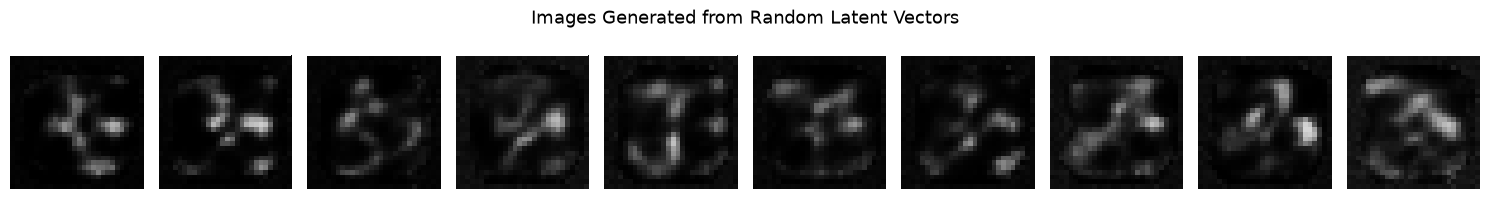

In [34]:
# Use the trained 64-dimensional autoencoder
best_model.eval()

# Set seed for reproducible sampling
torch.manual_seed(42)

# Generate 10 random latent vectors
random_latents = torch.randn(10, 64)

# Decode random vectors into images
with torch.no_grad():
    generated_images = best_model.model.decoder(random_latents)

print("Random latent vectors:", random_latents.shape)
print("Generated images:", generated_images.shape)

# Visualize generated images
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(
        generated_images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].axis("off")

plt.suptitle("Images Generated from Random Latent Vectors", fontsize=13)
plt.tight_layout()
plt.show()

### 11.5 Results and Discussion: Random Latent Sampling

The images generated from randomly sampled latent vectors are largely distorted and do not resemble clearly recognizable handwritten digits.

**Key observations:**
1. **Poor visual quality:** Most generated images contain blurry, disconnected, or irregular strokes rather than coherent digit shapes.
2. **Successful reconstruction versus unsuccessful generation:** The same decoder reconstructs recognizable MNIST digits when provided with latent representations produced by the trained encoder.
3. **Latent distribution mismatch:** A standard autoencoder does not explicitly constrain its encoded representations to follow a standard normal distribution.
4. **Unstructured random sampling:** Sampling vectors from a standard normal distribution may produce representations that differ substantially from those encountered by the decoder during training.

**Interpretation:**

The experiment demonstrates that accurate reconstruction does not automatically imply effective unconditional image generation.

The decoder is trained to reconstruct images from encoder-produced latent representations, but arbitrary random latent vectors are not guaranteed to correspond to meaningful images.

**Potential improvement:**

A Variational Autoencoder (VAE) introduces a probabilistic latent representation and regularizes its latent distribution toward a chosen prior, commonly a standard normal distribution.

This makes sampling from the prior more suitable for generating new images.

Other approaches include estimating the distribution of encoded training examples or sampling near known latent representations.

### 11.6 Investigating the Learned Latent Distribution

To investigate why random sampling produces poor images, we examine the numerical properties of latent representations produced by the trained encoder.

We encode MNIST training images and calculate the mean and standard deviation of the resulting latent values.

These statistics are compared with those of a standard normal distribution, which has mean 0 and standard deviation 1.

Differences between the encoded latent distribution and the sampling distribution may help explain why randomly sampled vectors produce unrealistic images.

In [35]:
# Use the trained encoder
best_model.eval()

# Collect latent representations from the training dataset
latent_batches = []

with torch.no_grad():
    for images, _ in train_loader:

        # Encode images into 64-dimensional latent vectors
        z = best_model.model.encoder(images)

        # Store latent vectors
        latent_batches.append(z.cpu())

# Combine all latent vectors
encoded_latents = torch.cat(latent_batches, dim=0)

# Calculate overall statistics
latent_mean = encoded_latents.mean().item()
latent_std = encoded_latents.std().item()

print("Encoded latent shape:", encoded_latents.shape)
print(f"\nEncoded latent mean: {latent_mean:.4f}")
print(f"Encoded latent standard deviation: {latent_std:.4f}")
print("\nStandard normal distribution:")
print("Expected mean: 0.0000")
print("Expected standard deviation: 1.0000")

Encoded latent shape: torch.Size([54000, 64])

Encoded latent mean: -0.2472
Encoded latent standard deviation: 3.4003

Standard normal distribution:
Expected mean: 0.0000
Expected standard deviation: 1.0000


### 11.7 Comparing Random and Encoder-Produced Latent Vectors

The trained encoder produced latent representations with an overall mean of approximately -0.2472 and a standard deviation of 3.4003.

These statistics differ from the standard normal distribution used for random sampling, which has mean 0 and standard deviation 1.

This suggests a mismatch between the random sampling distribution and the learned latent representations.

However, global mean and standard deviation alone do not fully characterize the 64-dimensional latent distribution.

To investigate the decoder's behavior further, we compare images generated from random latent vectors with reconstructions obtained from encoder-produced latent vectors.

Unlike random sampling, decoding representations from real images is expected to produce recognizable digits because the decoder was trained on such representations.

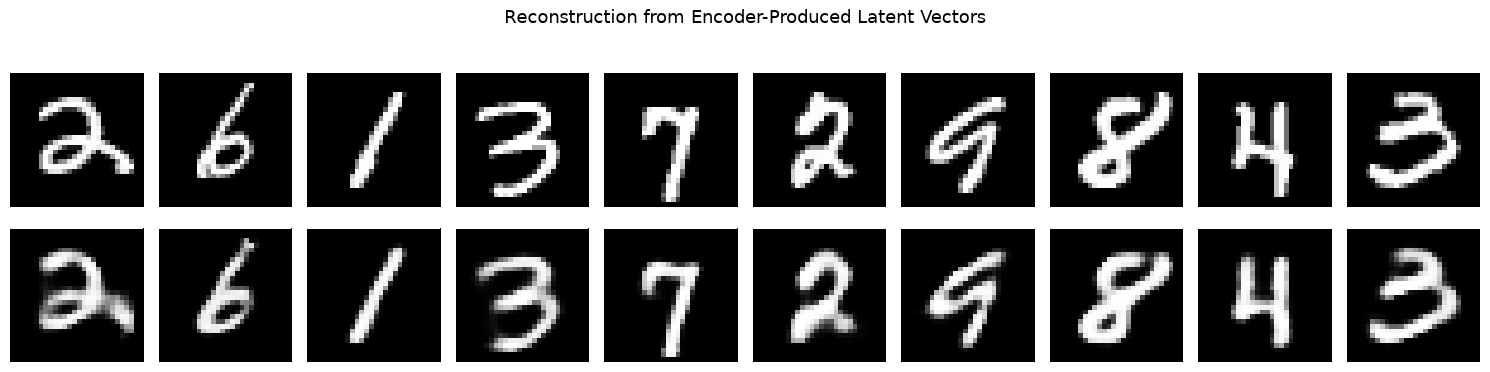

Encoded latent shape: torch.Size([10, 64])
Reconstructed image shape: torch.Size([10, 1, 28, 28])


In [36]:
# Use the trained model
best_model.eval()

# Retrieve 10 MNIST training images
images, _ = next(iter(train_loader))
images = images[:10]

with torch.no_grad():

    # Encode real images
    real_latents = best_model.model.encoder(images)

    # Decode the learned representations
    decoded_images = best_model.model.decoder(real_latents)

# Display results
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    # Original images
    axes[0, i].imshow(
        images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Images reconstructed from encoded latent vectors
    axes[1, i].imshow(
        decoded_images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for row in range(2):
        axes[row, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Reconstructed", fontsize=11)

plt.suptitle(
    "Reconstruction from Encoder-Produced Latent Vectors",
    fontsize=13
)

plt.tight_layout()
plt.show()

print("Encoded latent shape:", real_latents.shape)
print("Reconstructed image shape:", decoded_images.shape)

### 11.8 Latent Space Interpolation

Random sampling from a standard normal distribution produced distorted images, while decoding encoder-produced latent vectors successfully reconstructed recognizable digits.

We now investigate whether new images can be generated by interpolating between two encoded MNIST images.

Given two latent vectors \(z_A\) and \(z_B\), linear interpolation is defined as:

\[
z(\alpha)=(1-\alpha)z_A+\alpha z_B
\]

where \(\alpha\) varies between 0 and 1.

At \(\alpha=0\), the decoder receives the first latent vector. At \(\alpha=1\), it receives the second latent vector.

Intermediate values produce new latent vectors that lie along the straight line connecting the two representations.

**Hypothesis:** Interpolating between encoded examples may produce more coherent images than sampling arbitrary latent vectors from a standard normal distribution.

However, a standard autoencoder does not guarantee that intermediate latent vectors correspond to realistic images.

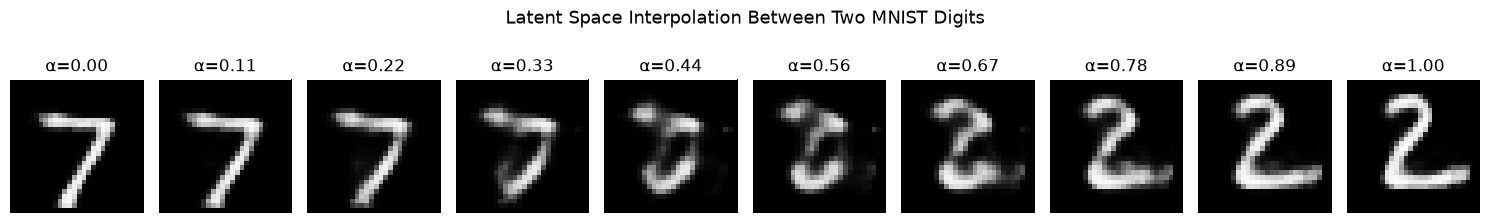

First digit label: 7
Second digit label: 2
Interpolated latent shape: torch.Size([10, 64])
Generated image shape: torch.Size([10, 1, 28, 28])


In [37]:
# Use the trained 64-dimensional autoencoder
best_model.eval()

# Select two different MNIST digits
image_a = test_dataset[0][0].unsqueeze(0)
image_b = test_dataset[1][0].unsqueeze(0)

with torch.no_grad():

    # Encode both images
    z_a = best_model.model.encoder(image_a)
    z_b = best_model.model.encoder(image_b)

    # Create 10 interpolation steps
    alphas = torch.linspace(0, 1, steps=10)

    # Generate intermediate latent vectors
    interpolated_latents = torch.cat([
        (1 - alpha) * z_a + alpha * z_b
        for alpha in alphas
    ], dim=0)

    # Decode interpolated latent vectors
    interpolated_images = best_model.model.decoder(
        interpolated_latents
    )

# Display interpolation
fig, axes = plt.subplots(1, 10, figsize=(15, 2.5))

for i in range(10):
    axes[i].imshow(
        interpolated_images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"α={alphas[i]:.2f}")
    axes[i].axis("off")

plt.suptitle(
    "Latent Space Interpolation Between Two MNIST Digits",
    fontsize=13
)

plt.tight_layout()
plt.show()

print("First digit label:", test_dataset[0][1])
print("Second digit label:", test_dataset[1][1])
print("Interpolated latent shape:", interpolated_latents.shape)
print("Generated image shape:", interpolated_images.shape)

### 11.9 Latent Interpolation Results and Discussion

The interpolation experiment demonstrates a gradual transformation between two handwritten MNIST digits.

The selected images represent the digits 7 and 2.

**Key observations:**
1. **Smooth transformation:** As the interpolation parameter increases from 0 to 1, the reconstructed image gradually changes from a recognizable 7 into a recognizable 2.
2. **Meaningful intermediate representations:** Intermediate latent vectors produce images containing recognizable stroke structures, suggesting that the decoder responds smoothly along the selected interpolation path.
3. **Ambiguous intermediate images:** Some intermediate images, particularly around α = 0.44–0.56, do not clearly resemble a specific handwritten digit.
4. **Comparison with random sampling:** Interpolation produces a more coherent visual sequence than the earlier experiment using randomly sampled standard-normal latent vectors.
5. **Limitations:** The experiment demonstrates smooth behavior along one interpolation path but does not establish that the entire latent space is suitable for realistic image generation.

**Interpretation:**

The results suggest that the trained autoencoder has learned a latent representation in which interpolation between certain encoded images produces gradual changes in reconstructed image structure.

However, standard autoencoders do not explicitly enforce a smooth, continuous, or probabilistically structured latent distribution.

Consequently, successful interpolation between selected examples does not guarantee successful generation from arbitrary latent vectors.

**Conclusion:**

Latent interpolation provides a practical way to explore the learned representation of an autoencoder and can produce meaningful intermediate images without training an additional generative model.

## 12. Conclusion

This assignment investigated the implementation, training, and evaluation of image autoencoders using PyTorch and Lightning on the MNIST handwritten digit dataset.

### 12.1 Summary of Experimental Results

Three autoencoder configurations were trained and evaluated.

| Model | Latent Dimension | Parameters | Validation MSE |
|---|---:|---:|---:|
| Fully Connected Autoencoder | 16 | 437,664 | 0.011822 |
| Fully Connected Autoencoder | 64 | 443,856 | **0.008654** |
| Convolutional Autoencoder | 16 | 61,329 | 0.010346 |

The fully connected autoencoder with a 64-dimensional latent representation achieved the lowest validation MSE.

This model was selected for final evaluation and achieved a test MSE of **0.008390** on 10,000 previously unseen MNIST images.

### 12.2 Key Findings

**1. Latent dimensionality affects reconstruction quality.**

Increasing the latent dimension from 16 to 64 reduced validation MSE by approximately 26.8%.

This suggests that a larger latent representation can preserve more information about the input images.

**2. Convolutional architectures provide effective spatial feature extraction.**

The convolutional autoencoder achieved approximately 12.5% lower validation MSE than the fully connected baseline with the same latent dimension.

It also required approximately 86% fewer trainable parameters.

This demonstrates the effectiveness of convolutional weight sharing and spatial feature extraction for the tested reconstruction task.

**3. Reconstruction quality does not guarantee successful image generation.**

Although the trained autoencoder reconstructed recognizable handwritten digits, sampling random latent vectors from a standard normal distribution produced mostly distorted images.

The encoded latent representations had an overall mean of -0.2472 and standard deviation of 3.4003, differing from the standard normal distribution used for sampling.

This provides evidence of a mismatch between the sampling distribution and the learned latent representations.

**4. Latent interpolation can produce meaningful image transitions.**

Interpolating between encoded representations of the digits 7 and 2 produced a gradual transformation between the two digit shapes.

However, some intermediate images remained ambiguous or distorted.

### 12.3 Limitations

The experiments have several limitations:

- All models were trained and evaluated exclusively on MNIST.
- Each configuration was trained once, so the variability across random seeds was not measured.
- Training was limited to 10 epochs.
- The compared architectures differed in parameter count as well as structure.
- Reconstruction quality was primarily assessed using pixel-level MSE and visual inspection.
- The standard autoencoder did not explicitly learn a probabilistic latent distribution suitable for unconditional generation.

### 12.4 Potential Future Improvements

Several extensions could improve reconstruction quality and generative capabilities:

1. Evaluate additional latent dimensions and convolutional architectures.
2. Repeat experiments using multiple random seeds.
3. Investigate more challenging image datasets.
4. Explore alternative reconstruction losses and evaluation metrics.
5. Implement a Variational Autoencoder (VAE) to encourage a more structured latent distribution and support probabilistic image generation.

### 12.5 Final Conclusion

The experiments demonstrate that autoencoders can learn compact representations of handwritten images and reconstruct unseen examples with relatively low error.

Both latent dimensionality and network architecture substantially influence reconstruction performance.

The bonus experiments also highlight an important distinction between reconstruction and generation: a standard autoencoder can reconstruct images successfully without learning a latent distribution that supports reliable random sampling.

These findings provide a foundation for understanding more advanced generative models, particularly Variational Autoencoders.

## 13. Reproducibility and Experimental Considerations

The experiments were implemented using PyTorch and PyTorch Lightning.

A random seed of 42 was used during model initialization to improve reproducibility.

All models were trained using the same MNIST training and validation subsets, batch size, optimizer, learning rate, loss function, and number of epochs.

However, exact numerical reproducibility is not guaranteed because training may be affected by random initialization, data shuffling, and implementation-specific numerical behavior.

The experiments use a single training run per configuration. Consequently, the reported differences represent observed performance under the tested settings rather than statistically established differences across repeated trials.

Future experiments could improve reliability by using explicitly controlled data-loading generators, repeated training runs with multiple random seeds, and reporting mean performance with standard deviations.

The final model was selected using validation performance and subsequently evaluated on the held-out test dataset.